<a href="https://colab.research.google.com/github/SoumayaBeliazidBouzaid/Notebooks/blob/main/notebooks/07_pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/07_pandas.ipynb)

# Python pour la physique — 7. Pandas : manipuler des tableaux de données

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !

In [1]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


# Pourquoi pandas ?

Lors d'une séance de travaux pratiques, on obtient typiquement un **tableau de mesures** : chaque ligne est une mesure (ou une expérience), chaque colonne une grandeur (longueur, durée, température, nom de l'opérateur…). Un tableau NumPy convient bien aux données purement numériques et homogènes, mais il manque :

- de **noms de colonnes** ;
- de la possibilité de mélanger **nombres et texte** ;
- d'outils pour gérer les **valeurs manquantes** ;
- d'opérations de regroupement, de tri, de fusion…

**pandas** est le « tableur Python » : son objet principal, le `DataFrame`, est un tableau à colonnes nommées, avec de puissants mécanismes de sélection et de regroupement. Il lit et écrit les fichiers CSV et Excel.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Créer un DataFrame

## À partir de listes ou de tableaux

Un `DataFrame` peut être vu comme un dictionnaire de « séries » 1D (listes ou tableaux NumPy). Voici des mesures de la période d'un pendule pour différentes longueurs :

In [3]:
mesures = pd.DataFrame({
    'longueur_m': [0.20, 0.40, 0.60, 0.80, 1.00, 1.20],
    'periode_s':  [0.90, 1.27, 1.55, 1.79, 2.01, 2.20],
})
mesures

,longueur_m,periode_s
0,0.2,0.90
1,0.4,1.27
2,0.6,1.55
3,0.8,1.79
4,1.0,2.01
5,1.2,2.20


On peut aussi partir de tableaux NumPy :

In [4]:
t = np.linspace(-6, 6, 20)
pd.DataFrame({'t': t, 'sin': np.sin(t), 'cos': np.cos(t)}).head()

,t,sin,cos
0,-6.000000,0.279415,0.960170
1,-5.368421,0.792419,0.609977
2,-4.736842,0.999701,0.024451
3,-4.105263,0.821291,-0.570509
4,-3.473684,0.326021,-0.945363


## En lisant un fichier CSV

Dans la pratique, les données viennent d'un fichier : un export de logiciel d'acquisition, un tableur, un fichier de l'enseignant. Fabriquons d'abord un petit fichier CSV de TP à partir de données simulées, pour pouvoir le relire ensuite :

In [5]:
rng = np.random.default_rng(12)
noms = ['Alice', 'Bruno', 'Chloé', 'David']
lignes = []
for operateur in noms:
    for L in [0.25, 0.50, 0.75, 1.00]:
        T = 2 * np.pi * np.sqrt(L / 9.81) * (1 + rng.normal(0, 0.02))
        lignes.append((operateur, L, round(T, 3), 0.1 if L < 0.7 else 0.2))
df_brut = pd.DataFrame(lignes, columns=['operateur', 'longueur_m', 'periode_s', 'masse_kg'])
df_brut.loc[5, 'periode_s'] = np.nan          # une mesure oubliée
df_brut.to_csv('pendule.csv', sep=';', index=False, decimal=',')
print(open('pendule.csv').read()[:300])

operateur;longueur_m;periode_s;masse_kg
Alice;0,25;1,003;0,1
Alice;0,5;1,448;0,1
Alice;0,75;1,763;0,2
Alice;1,0;2,035;0,2
Bruno;0,25;1,036;0,1
Bruno;0,5;;0,1
Bruno;0,75;1,716;0,2
Bruno;1,0;1,953;0,2
Chloé;0,25;1,001;0,1
Chloé;0,5;1,447;0,1
Chloé;0,75;1,737;0,2
Chloé;1,0;2,026;0,2
David;0,25;0,965;0,


Ce fichier utilise le **point-virgule** comme séparateur et la **virgule** comme séparateur décimal (comme dans un tableur français). Lisons-le avec `read_csv` :

In [6]:
df = pd.read_csv('pendule.csv', sep=';', decimal=',')
df

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2
4,Bruno,0.25,1.036,0.1
5,Bruno,0.50,NaN,0.1
6,Bruno,0.75,1.716,0.2
7,Bruno,1.00,1.953,0.2
8,Chloé,0.25,1.001,0.1
9,Chloé,0.50,1.447,0.1


> 💡 **Astuce**
>
> **Avec Google Drive** : pour lire un fichier de votre Drive, montez-le d'abord :
>
> ```python
> from google.colab import drive
> drive.mount('/content/drive')
> df = pd.read_csv('/content/drive/MyDrive/mes_donnees/pendule.csv', sep=';', decimal=',')
> ```
>
> Pour un fichier Excel : `pd.read_excel('fichier.xlsx')`. Pour importer un fichier depuis votre ordinateur : `from google.colab import files; files.upload()`.



> ⚠️ **Attention**
>
> **Valeurs manquantes.** Une période est manquante dans le fichier (`NaN`, *Not a Number*). Si les valeurs manquantes sont codées autrement (par exemple `.` ou `-999`), indiquez-le avec `na_values=...` dans `read_csv`, sinon les statistiques seront fausses.

# Explorer les données

In [7]:
df.shape          # (lignes, colonnes)

(16, 4)

In [8]:
df.columns        # noms des colonnes

Index(['operateur', 'longueur_m', 'periode_s', 'masse_kg'], dtype='object')

In [9]:
df.head()         # les premières lignes (df.tail() pour les dernières)

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2
4,Bruno,0.25,1.036,0.1


In [10]:
df.info()         # types des colonnes et nombre de valeurs non manquantes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   operateur   16 non-null     object 
 1   longueur_m  16 non-null     float64
 2   periode_s   15 non-null     float64
 3   masse_kg    16 non-null     float64
dtypes: float64(3), object(1)
memory usage: 644.0+ bytes


La méthode `describe` donne un résumé statistique rapide, pratique pour un gros tableau :

In [11]:
df.describe()

,longueur_m,periode_s,masse_kg
count,16.000000,15.000000,16.00000
mean,0.625000,1.555733,0.15000
std,0.288675,0.403365,0.05164
min,0.250000,0.965000,0.10000
25%,0.437500,1.229500,0.10000
50%,0.625000,1.706000,0.15000
75%,0.812500,1.858000,0.20000
max,1.000000,2.077000,0.20000


# Sélectionner des données

**Une colonne**, par son nom (le résultat est une `Series`) :

In [12]:
df['periode_s']

,periode_s
0,1.003
1,1.448
2,1.763
3,2.035
4,1.036
5,NaN
6,1.716
7,1.953
8,1.001
9,1.447


**Plusieurs colonnes** (le résultat est un `DataFrame`) :

In [13]:
df[['operateur', 'periode_s']]

,operateur,periode_s
0,Alice,1.003
1,Alice,1.448
2,Alice,1.763
3,Alice,2.035
4,Bruno,1.036
5,Bruno,NaN
6,Bruno,1.716
7,Bruno,1.953
8,Chloé,1.001
9,Chloé,1.447


**Des lignes**, par position avec `iloc`, ou par étiquette avec `loc` :

In [14]:
df.iloc[0:3]                   # trois premières lignes

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2


In [15]:
df.loc[0:3, ['longueur_m', 'periode_s']]   # attention : avec loc, la borne 3 est incluse

,longueur_m,periode_s
0,0.25,1.003
1,0.50,1.448
2,0.75,1.763
3,1.00,2.035


**Des lignes qui vérifient une condition** (filtre booléen, comme les masques NumPy) :

In [16]:
df[df['operateur'] == 'Alice']

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2


In [17]:
df[(df['longueur_m'] >= 0.5) & (df['masse_kg'] == 0.2)]    # & = ET, | = OU, ~ = NON

,operateur,longueur_m,periode_s,masse_kg
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2
6,Bruno,0.75,1.716,0.2
7,Bruno,1.00,1.953,0.2
10,Chloé,0.75,1.737,0.2
11,Chloé,1.00,2.026,0.2
14,David,0.75,1.706,0.2
15,David,1.00,2.077,0.2


Moyenne d'une sélection :

In [18]:
df[df['operateur'] == 'Alice']['periode_s'].mean()

np.float64(1.56225)

# Créer de nouvelles colonnes

Les opérations se font colonne par colonne, comme avec NumPy. Calculons la valeur de $g$ déduite de chaque mesure, avec $g = 4\pi^2 L / T^2$ :

In [19]:
df['g'] = 4 * np.pi**2 * df['longueur_m'] / df['periode_s']**2
df.head()

,operateur,longueur_m,periode_s,masse_kg,g
0,Alice,0.25,1.003,0.1,9.810652
1,Alice,0.50,1.448,0.1,9.414399
2,Alice,0.75,1.763,0.2,9.526127
3,Alice,1.00,2.035,0.2,9.533029
4,Bruno,0.25,1.036,0.1,9.195603


Les fonctions NumPy s'appliquent directement aux colonnes :

In [20]:
df['log_T'] = np.log10(df['periode_s'])
df[['periode_s', 'log_T']].head(3)

,periode_s,log_T
0,1.003,0.001301
1,1.448,0.160769
2,1.763,0.246252


# Valeurs manquantes

In [21]:
df.isna().sum()          # nombre de valeurs manquantes par colonne

,0
operateur,0
longueur_m,0
periode_s,1
masse_kg,0
g,1
log_T,1


In [22]:
df[df['periode_s'].isna()]     # la ligne concernée

,operateur,longueur_m,periode_s,masse_kg,g,log_T
5,Bruno,0.5,NaN,0.1,NaN,NaN


On peut **supprimer** les lignes incomplètes, ou **remplacer** les valeurs manquantes :

In [23]:
df_propre = df.dropna()                  # supprime les lignes contenant un NaN
print(len(df), "->", len(df_propre))

16 -> 15


In [24]:
df['periode_s'].fillna(df['periode_s'].mean()).head(8)   # remplace par la moyenne (à utiliser avec prudence !)

,periode_s
0,1.003000
1,1.448000
2,1.763000
3,2.035000
4,1.036000
5,1.555733
6,1.716000
7,1.953000


> ⚠️ **Attention**
>
> Remplacer une mesure manquante par une moyenne **invente** une donnée. En physique, il vaut généralement mieux ignorer la mesure manquante. Notez que `mean()`, `std()`, etc. ignorent déjà les `NaN` par défaut.

# Regrouper et agréger : `groupby`

`groupby` découpe un tableau selon les valeurs d'une variable catégorielle (ici l'opérateur), puis calcule une statistique pour chaque groupe :

In [25]:
df_propre = df.dropna()
df_propre.groupby('operateur')['g'].mean()

,g
operateur,
Alice,9.571052
Bruno,9.867020
Chloé,9.677167
David,9.917831


Plusieurs statistiques à la fois avec `agg` :

In [26]:
df_propre.groupby('operateur')['g'].agg(['count', 'mean', 'std'])

,count,mean,std
operateur,,,
Alice,4,9.571052,0.168733
Bruno,3,9.867020,0.599911
Chloé,4,9.677167,0.195186
David,4,9.917831,0.617755


On peut regrouper selon plusieurs colonnes :

In [27]:
df_propre.groupby(['masse_kg', 'longueur_m'])['periode_s'].mean()

masse_kg  longueur_m
0.1       0.25          1.001250
          0.50          1.439333
0.2       0.75          1.730500
          1.00          2.022750
Name: periode_s, dtype: float64

Et obtenir directement toutes les moyennes d'un tableau groupé :

In [28]:
df_propre.groupby('operateur')[['periode_s', 'g']].mean()

,periode_s,g
operateur,,
Alice,1.562250,9.571052
Bruno,1.568333,9.867020
Chloé,1.552750,9.677167
David,1.542750,9.917831


> 📝 **Note**
>
> D'autres fonctions d'agrégation courantes : `median`, `min`, `max`, `sum`, `count` (pratique pour compter les valeurs manquantes dans chaque sous-ensemble).


Un **diagramme en boîtes** (*boxplot*) compare rapidement les distributions des groupes :

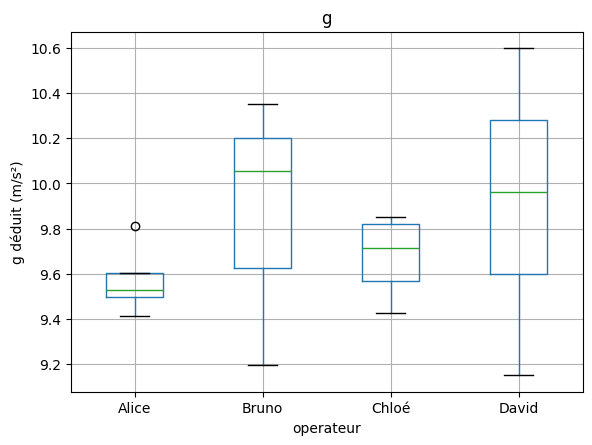

In [29]:
df_propre.boxplot(column='g', by='operateur')
plt.suptitle("")
plt.ylabel("g déduit (m/s²)")
plt.show()

> **Exercice**
>
> 1. Quelle est la valeur moyenne de $g$ pour l'ensemble des mesures valides ?
> 2. Combien de mesures valides chaque opérateur a-t-il faites ?
> 3. Quelle est la période moyenne pour chaque longueur ?

In [32]:
# Votre code ici

import pandas as pd

# 1. Afficher les informations du DataFrame
print("Colonnes disponibles :")
print(df.columns.tolist())

print("\nAperçu des données :")
print(df.head())

# Nettoyer les noms des colonnes
df.columns = df.columns.str.strip().str.lower()

# 2. Identifier les colonnes
print("\nNoms des colonnes après nettoyage :")
print(df.columns.tolist())

# 3. Identifier les mesures valides
# Si une colonne de validité existe, on l'utilise.
colonnes_validite = ["valide", "validite", "valid", "is_valid"]

col_validite = next(
    (c for c in colonnes_validite if c in df.columns), None
)

if col_validite is not None:
    valeurs = df[col_validite].astype(str).str.lower().str.strip()
    mesures_valides = df[
        valeurs.isin(["true", "1", "oui", "yes", "valide"])
    ].copy()
else:
    # Si aucune colonne de validité n'existe,
    # on conserve les lignes sans valeurs manquantes.
    mesures_valides = df.dropna().copy()
    print("\nAttention : aucune colonne de validité trouvée.")
    print("Les lignes sans valeurs manquantes sont utilisées.")

# 4. Question 1 : valeur moyenne de g
if "g" in mesures_valides.columns:
    g_moyen = pd.to_numeric(
        mesures_valides["g"], errors="coerce"
    ).mean()

    print("\n1. Valeur moyenne de g :")
    print(g_moyen, "m/s²")
else:
    print("\nColonne g introuvable.")

# 5. Question 2 : nombre de mesures valides par opérateur
col_operateur = next(
    (c for c in ["operateur", "opérateur", "operator"]
     if c in mesures_valides.columns), None
)

if col_operateur:
    print("\n2. Nombre de mesures valides par opérateur :")
    print(mesures_valides.groupby(col_operateur).size())
else:
    print("\nColonne opérateur introuvable.")

# 6. Question 3 : période moyenne pour chaque longueur
col_longueur = next(
    (c for c in ["longueur", "length", "l"]
     if c in mesures_valides.columns), None
)

col_periode = next(
    (c for c in ["periode", "période", "period", "t"]
     if c in mesures_valides.columns), None
)

if col_longueur and col_periode:
    mesures_valides[col_periode] = pd.to_numeric(
        mesures_valides[col_periode], errors="coerce"
    )

    print("\n3. Période moyenne pour chaque longueur :")
    print(
        mesures_valides.groupby(col_longueur)[col_periode]
        .mean()
    )
else:
    print("\nColonne longueur ou période introuvable.")


Colonnes disponibles :
['operateur', 'longueur_m', 'periode_s', 'masse_kg', 'g', 'log_T']

Aperçu des données :
  operateur  longueur_m  periode_s  masse_kg         g     log_T
0     Alice        0.25      1.003       0.1  9.810652  0.001301
1     Alice        0.50      1.448       0.1  9.414399  0.160769
2     Alice        0.75      1.763       0.2  9.526127  0.246252
3     Alice        1.00      2.035       0.2  9.533029  0.308564
4     Bruno        0.25      1.036       0.1  9.195603  0.015360

Noms des colonnes après nettoyage :
['operateur', 'longueur_m', 'periode_s', 'masse_kg', 'g', 'log_t']

Attention : aucune colonne de validité trouvée.
Les lignes sans valeurs manquantes sont utilisées.

1. Valeur moyenne de g :
9.751017258593095 m/s²

2. Nombre de mesures valides par opérateur :
operateur
Alice    4
Bruno    3
Chloé    4
David    4
dtype: int64

Colonne longueur ou période introuvable.


In [31]:
#@title Solution { display-mode: "form" }
print("g moyen :", df_propre['g'].mean())
print(df_propre.groupby('operateur')['g'].count())
print(df_propre.groupby('longueur_m')['periode_s'].mean())

g moyen : 9.751017258593095
operateur
Alice    4
Bruno    3
Chloé    4
David    4
Name: g, dtype: int64
longueur_m
0.25    1.001250
0.50    1.439333
0.75    1.730500
1.00    2.022750
Name: periode_s, dtype: float64


# Trier, renommer, supprimer

In [33]:
df_propre.sort_values('g', ascending=False).head(3)       # les 3 plus grandes valeurs de g

,operateur,longueur_m,periode_s,masse_kg,g,log_T
12,David,0.25,0.965,0.1,10.598517,-0.015473
7,Bruno,1.00,1.953,0.2,10.350355,0.290702
14,David,0.75,1.706,0.2,10.173326,0.231979


In [34]:
df_propre.rename(columns={'periode_s': 'T (s)', 'longueur_m': 'L (m)'}).head(3)

,operateur,L (m),T (s),masse_kg,g,log_T
0,Alice,0.25,1.003,0.1,9.810652,0.001301
1,Alice,0.50,1.448,0.1,9.414399,0.160769
2,Alice,0.75,1.763,0.2,9.526127,0.246252


In [35]:
df_propre.drop(columns=['log_T']).head(3)

,operateur,longueur_m,periode_s,masse_kg,g
0,Alice,0.25,1.003,0.1,9.810652
1,Alice,0.50,1.448,0.1,9.414399
2,Alice,0.75,1.763,0.2,9.526127


# Fusionner des tableaux

`merge` associe deux tableaux selon une colonne commune, comme une jointure de base de données. Par exemple, on ajoute à chaque mesure l'incertitude de l'instrument de chaque longueur :

In [36]:
incertitudes = pd.DataFrame({'longueur_m': [0.25, 0.50, 0.75, 1.00],
                             'u_L_mm': [1, 1, 2, 2]})
fusion = df_propre.merge(incertitudes, on='longueur_m')
fusion[['operateur', 'longueur_m', 'u_L_mm']].head()

,operateur,longueur_m,u_L_mm
0,Alice,0.25,1
1,Alice,0.50,1
2,Alice,0.75,2
3,Alice,1.00,2
4,Bruno,0.25,1


`pd.concat([df1, df2])` met deux tableaux l'un sous l'autre (par exemple les données de deux groupes de TP).

# Représenter graphiquement

Les `DataFrame` ont une méthode `plot` qui appelle Matplotlib :

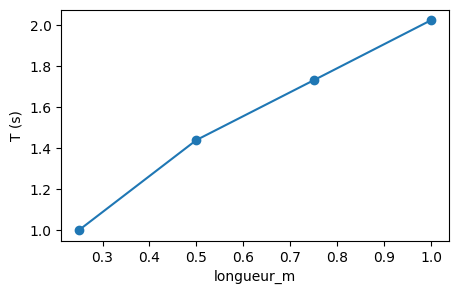

In [37]:
moyennes = df_propre.groupby('longueur_m')['periode_s'].mean()
moyennes.plot(marker='o', figsize=(5, 3))
plt.ylabel("T (s)")
plt.show()

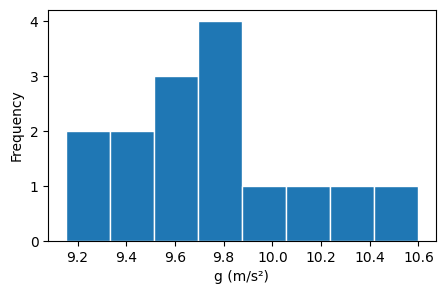

In [38]:
df_propre['g'].plot(kind='hist', bins=8, edgecolor='white', figsize=(5, 3))
plt.xlabel("g (m/s²)")
plt.show()

Pour des figures plus abouties, on extrait les colonnes et on utilise Matplotlib directement :

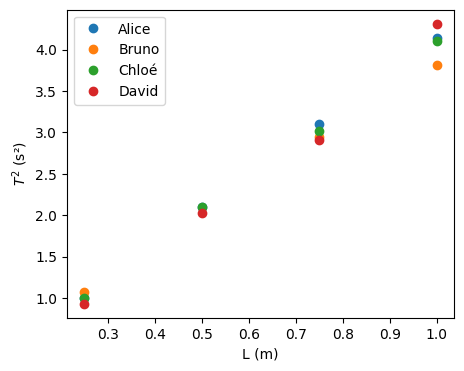

In [39]:
fig, ax = plt.subplots(figsize=(5, 4))
for operateur, groupe in df_propre.groupby('operateur'):
    ax.plot(groupe['longueur_m'], groupe['periode_s']**2, 'o', label=operateur)
ax.set_xlabel("L (m)")
ax.set_ylabel(r"$T^2$ (s²)")
ax.legend()
plt.show()

# Série temporelle : une courbe de refroidissement

Un autre cas typique : un fichier d'acquisition avec le temps en première colonne. Simulons le refroidissement d'un liquide (loi de Newton), enregistré toutes les 30 s :

In [40]:
rng = np.random.default_rng(5)
temps = np.arange(0, 1800, 30)
T_amb, T0, tau = 21.0, 85.0, 600.0
T_mes = T_amb + (T0 - T_amb) * np.exp(-temps / tau) + rng.normal(0, 0.3, temps.size)

refroid = pd.DataFrame({'t_s': temps, 'T_C': T_mes.round(2)})
refroid.to_csv('refroidissement.csv', index=False)
refroid = pd.read_csv('refroidissement.csv')
refroid.head()

,t_s,T_C
0,0,84.76
1,30,81.48
2,60,78.84
3,90,76.21
4,120,73.74


Ajoutons une colonne en minutes et calculons une moyenne glissante pour lisser le bruit :

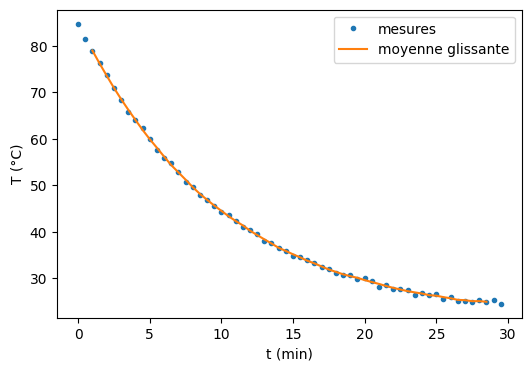

In [41]:
refroid['t_min'] = refroid['t_s'] / 60
refroid['T_lisse'] = refroid['T_C'].rolling(window=5, center=True).mean()

plt.figure(figsize=(6, 4))
plt.plot(refroid['t_min'], refroid['T_C'], '.', label="mesures")
plt.plot(refroid['t_min'], refroid['T_lisse'], '-', label="moyenne glissante")
plt.xlabel("t (min)"); plt.ylabel("T (°C)"); plt.legend()
plt.show()

# Pandas + SciPy : ajuster un modèle

Les colonnes d'un `DataFrame` sont directement utilisables avec `curve_fit` (carnet 5). Ajustons la loi de Newton $T(t) = T_\text{amb} + (T_0 - T_\text{amb})\,e^{-t/\tau}$ :

In [46]:

from scipy.optimize import curve_fit

def newton(t, T_amb, delta, tau):
    return T_amb + delta * np.exp(-t / tau)

popt, pcov = curve_fit(
    newton, refroid['t_s'], refroid['T_C'],
    p0=[20, 60, 500]
)

incert = np.sqrt(np.diag(pcov))

print(f"T_amb = {popt[0]:.2f} ± {incert[0]:.2f} °C")
print(f"tau   = {popt[2]:.0f} ± {incert[2]:.0f} s")

refroid['T_modele'] = newton(refroid['t_s'], *popt)
refroid['residu'] = refroid['T_C'] - refroid['T_modele']

print("écart-type des résidus :", round(refroid['residu'].std(), 3), "°C")


T_amb = 21.06 ± 0.14 °C
tau   = 596 ± 4 s
écart-type des résidus : 0.283 °C


# Enregistrer ses résultats

In [47]:
resultats = df_propre.groupby('operateur')['g'].agg(['count', 'mean', 'std']).round(3)
resultats.to_csv('resultats_g.csv')
resultats

,count,mean,std
operateur,,,
Alice,4,9.571,0.169
Bruno,3,9.867,0.600
Chloé,4,9.677,0.195
David,4,9.918,0.618


Pour Excel : `resultats.to_excel('resultats_g.xlsx')`. Pour récupérer un fichier créé dans Colab sur votre ordinateur :

```python
from google.colab import files
files.download('resultats_g.csv')
```

Ou, pour l'enregistrer dans Google Drive : `resultats.to_csv('/content/drive/MyDrive/resultats_g.csv')` (après avoir monté le Drive).

# Exercice de synthèse : la loi d'Ohm

Un groupe a mesuré l'intensité $I$ (en mA) pour plusieurs tensions $U$ (en V) aux bornes de trois résistances. Voici le tableau :

In [48]:
rng = np.random.default_rng(21)
U = np.arange(1, 11)
donnees_ohm = pd.concat([
    pd.DataFrame({'resistance': nom, 'U_V': U,
                  'I_mA': 1000 * U / R + rng.normal(0, 0.15, U.size)})
    for nom, R in [('R1', 100.0), ('R2', 220.0), ('R3', 470.0)]
], ignore_index=True)
donnees_ohm.head()

,resistance,U_V,I_mA
0,R1,1,10.053816
1,R1,2,20.226602
2,R1,3,29.732050
3,R1,4,40.252992
4,R1,5,49.992902


1. Combien de mesures y a-t-il par résistance ?
2. Ajoutez une colonne `I_A` (intensité en ampères).
3. Pour **chaque résistance**, ajustez une droite $U = R\,I$ (utilisez `np.polyfit` sur `I_A` et `U_V`) et affichez la valeur de $R$ trouvée.
4. Tracez les trois séries de points et leurs droites ajustées sur un même graphique, avec une légende.

1. Nombre de mesures par résistance :
resistance
R1    10
R2    10
R3    10
Name: U_V, dtype: int64

Nombre total de mesures : 30

2. Tableau avec la colonne I_A :
  resistance  U_V       I_mA       I_A
0         R1    1  10.053816  0.010054
1         R1    2  20.226602  0.020227
2         R1    3  29.732050  0.029732
3         R1    4  40.252992  0.040253
4         R1    5  49.992902  0.049993

3. Résistances trouvées :
R1 : R = 100.11 Ω
R2 : R = 219.08 Ω
R3 : R = 468.85 Ω


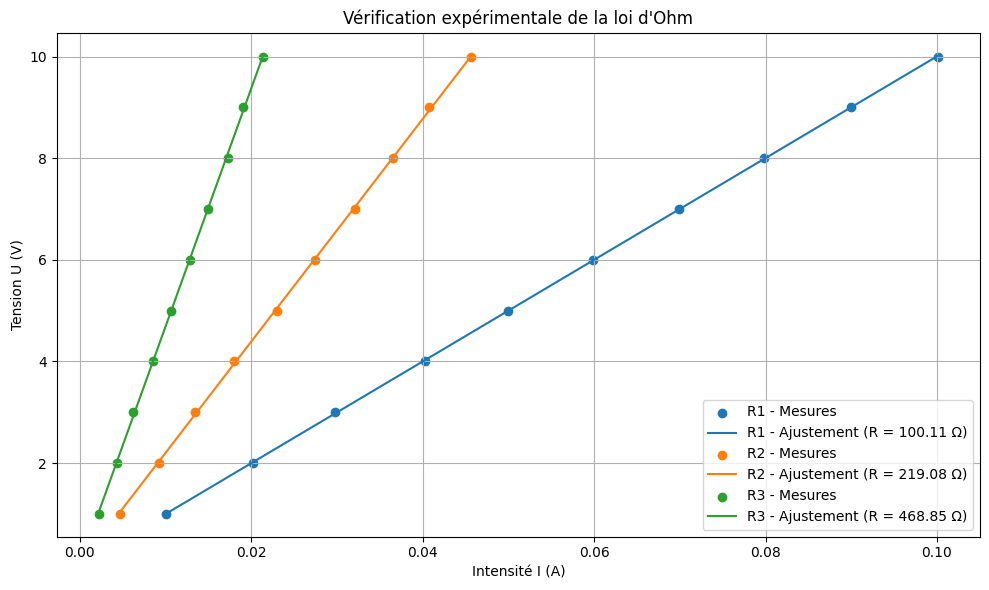

In [53]:
# Votre code ici

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Création des données
rng = np.random.default_rng(21)
U = np.arange(1, 11)

donnees_ohm = pd.concat([
    pd.DataFrame({
        'resistance': nom,
        'U_V': U,
        'I_mA': 1000 * U / R + rng.normal(0, 0.15, U.size)
    })
    for nom, R in [('R1', 100.0), ('R2', 220.0), ('R3', 470.0)]
], ignore_index=True)

# 2. Nombre de mesures par résistance
print("1. Nombre de mesures par résistance :")
print(donnees_ohm.groupby('resistance')['U_V'].count())
print("\nNombre total de mesures :", len(donnees_ohm))

# 3. Conversion de mA en A
donnees_ohm['I_A'] = donnees_ohm['I_mA'] / 1000

print("\n2. Tableau avec la colonne I_A :")
print(donnees_ohm.head())

# 4. Ajustement linéaire pour chaque résistance
print("\n3. Résistances trouvées :")
resistances = {}

for nom, groupe in donnees_ohm.groupby('resistance'):
    R, b = np.polyfit(groupe['I_A'], groupe['U_V'], 1)
    resistances[nom] = (R, b)
    print(f"{nom} : R = {R:.2f} Ω")

# 5. Tracé des points et des droites ajustées
plt.figure(figsize=(10, 6))

for nom, groupe in donnees_ohm.groupby('resistance'):
    # Points expérimentaux
    plt.scatter(groupe['I_A'], groupe['U_V'], label=f'{nom} - Mesures')

    # Droite ajustée
    R, b = resistances[nom]
    I_ligne = np.linspace(groupe['I_A'].min(),
                          groupe['I_A'].max(), 100)
    U_ligne = R * I_ligne + b

    plt.plot(I_ligne, U_ligne,
             label=f'{nom} - Ajustement (R = {R:.2f} Ω)')

plt.xlabel('Intensité I (A)')
plt.ylabel('Tension U (V)')
plt.title("Vérification expérimentale de la loi d'Ohm")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

resistance
R1    10
R2    10
R3    10
dtype: int64
R1 : R = 100.1 Ω
R2 : R = 219.1 Ω
R3 : R = 468.8 Ω


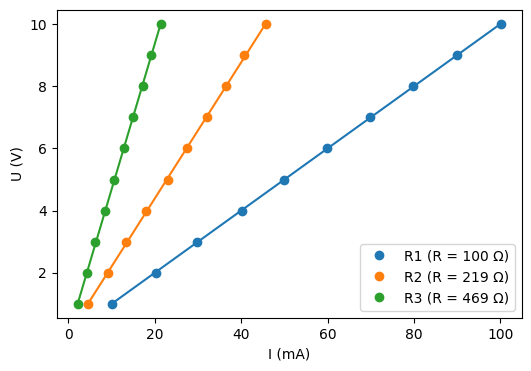

In [51]:
#@title Solution { display-mode: "form" }
print(donnees_ohm.groupby('resistance').size())

donnees_ohm['I_A'] = donnees_ohm['I_mA'] / 1000

plt.figure(figsize=(6, 4))
for nom, groupe in donnees_ohm.groupby('resistance'):
    pente, ordonnee = np.polyfit(groupe['I_A'], groupe['U_V'], 1)
    print(f"{nom} : R = {pente:.1f} Ω")
    plt.plot(groupe['I_A'] * 1000, groupe['U_V'], 'o', label=f"{nom} (R = {pente:.0f} Ω)")
    plt.plot(groupe['I_A'] * 1000, pente * groupe['I_A'] + ordonnee, '-', color=plt.gca().lines[-1].get_color())
plt.xlabel("I (mA)"); plt.ylabel("U (V)"); plt.legend()
plt.show()

# Aide-mémoire

| Je veux…                         | Commande                                          |
| -------------------------------- | ------------------------------------------------- |
| lire un CSV                      | `pd.read_csv('f.csv', sep=';', decimal=',')`      |
| lire un fichier Excel            | `pd.read_excel('f.xlsx')`                         |
| aperçu / résumé                  | `df.head()`, `df.info()`, `df.describe()`         |
| une colonne / plusieurs colonnes | `df['a']` / `df[['a', 'b']]`                      |
| filtrer des lignes               | `df[df['a'] > 3]`                                 |
| nouvelle colonne                 | `df['c'] = df['a'] * df['b']`                     |
| valeurs manquantes               | `df.isna().sum()`, `df.dropna()`                  |
| statistiques par groupe          | `df.groupby('col')['a'].agg(['mean', 'std'])`     |
| trier                            | `df.sort_values('a')`                             |
| fusionner / empiler              | `df1.merge(df2, on='col')` / `pd.concat([df1, df2])` |
| enregistrer                      | `df.to_csv('f.csv', index=False)`                 |
| tracer                           | `df.plot(x='a', y='b')`                           |

# Pour aller plus loin

- La [documentation de pandas](https://pandas.pydata.org/docs/) et son guide « 10 minutes to pandas » (en anglais).
- **Seaborn** (`import seaborn as sns`) : graphiques statistiques élégants construits sur pandas et Matplotlib.
- **Statsmodels** : modèles linéaires, régressions et tests statistiques avec des tableaux pandas.

---

*Fin du carnet 7.*